Loading the model...

Testing prediction on a single image...
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
Prediction: Pneumonia with probability 68.68%


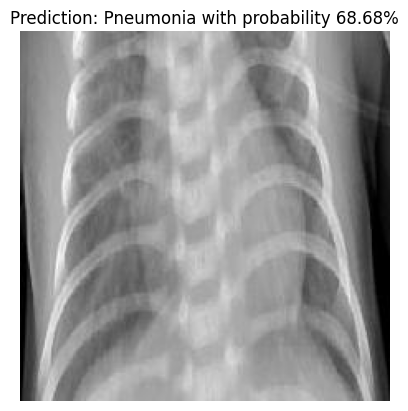


Generating Grad-CAM for layer: stem_conv...


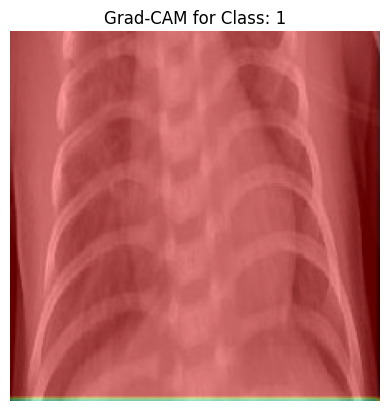


Generating Grad-CAM for layer: block1a_se_reduce...


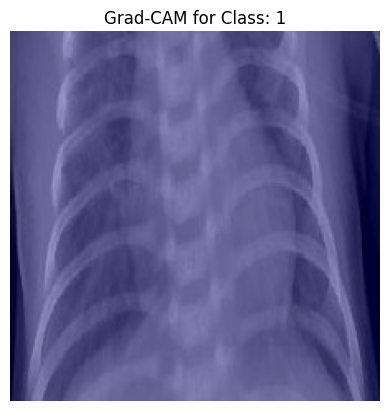


Generating Grad-CAM for layer: block1a_se_expand...


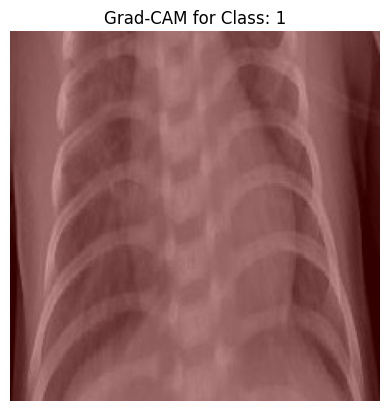


Generating Grad-CAM for layer: block1a_project_conv...


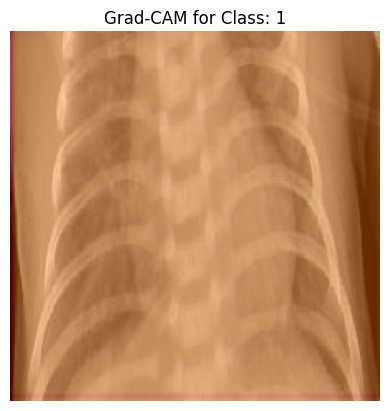


Generating Grad-CAM for layer: block2a_expand_conv...


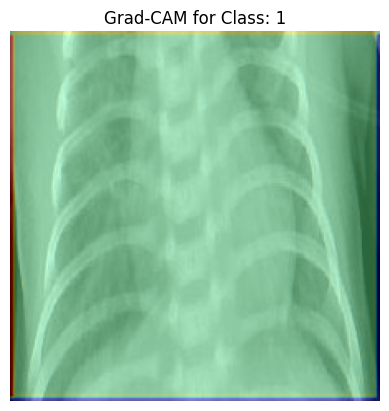


Generating Grad-CAM for layer: block2a_se_reduce...


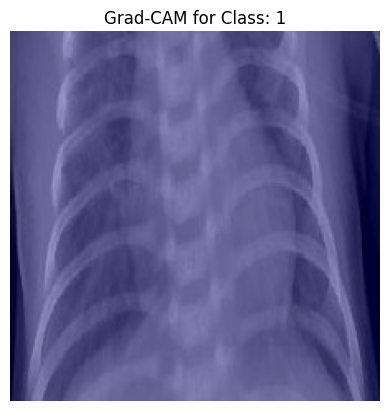


Generating Grad-CAM for layer: block2a_se_expand...


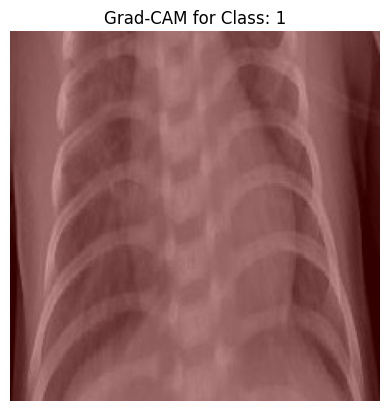


Generating Grad-CAM for layer: block2a_project_conv...


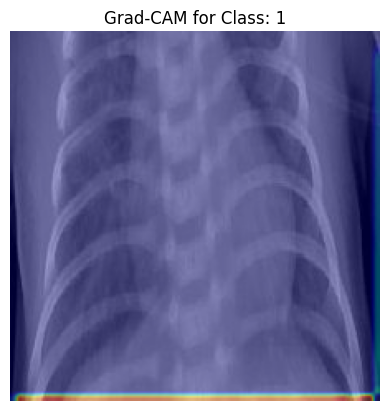


Generating Grad-CAM for layer: block2b_expand_conv...


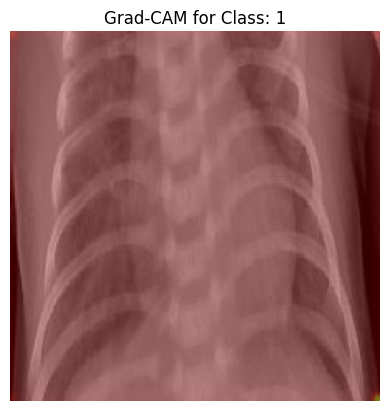


Generating Grad-CAM for layer: block2b_se_reduce...


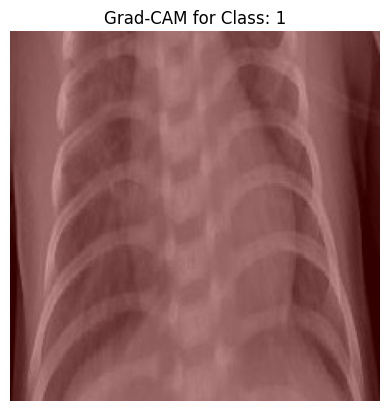


Generating Grad-CAM for layer: block2b_se_expand...


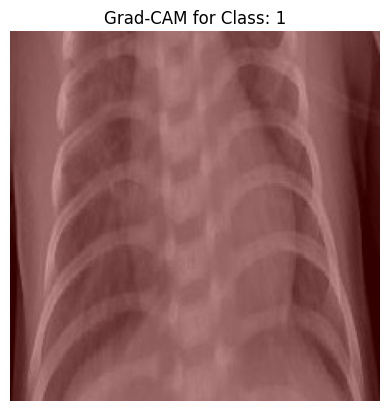


Generating Grad-CAM for layer: block2b_project_conv...


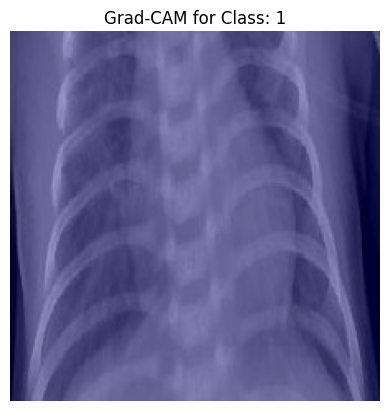


Generating Grad-CAM for layer: block3a_expand_conv...


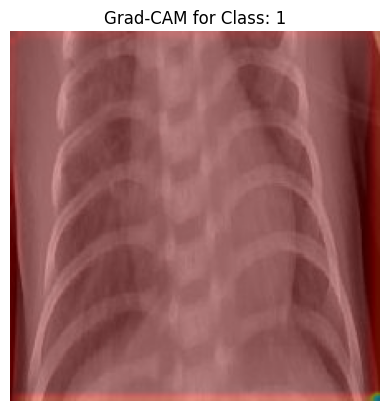


Generating Grad-CAM for layer: block3a_se_reduce...


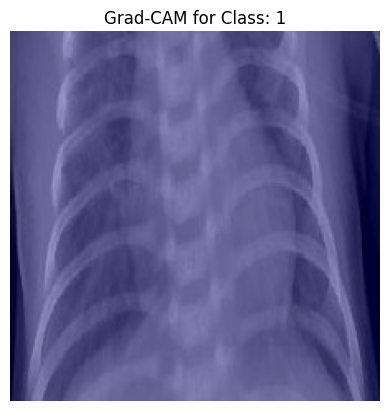


Generating Grad-CAM for layer: block3a_se_expand...


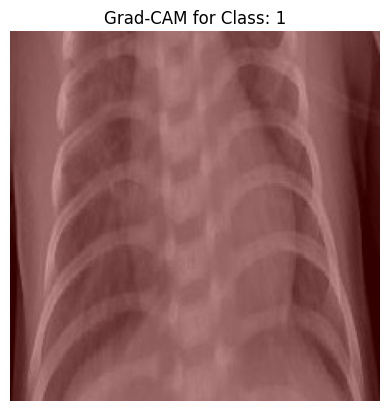


Generating Grad-CAM for layer: block3a_project_conv...


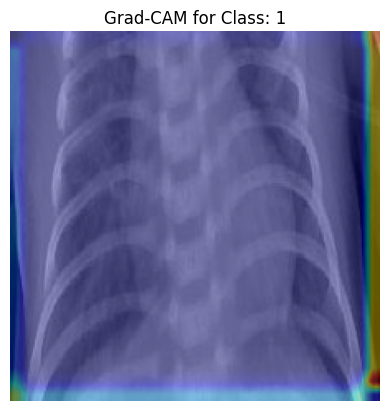


Generating Grad-CAM for layer: block3b_expand_conv...


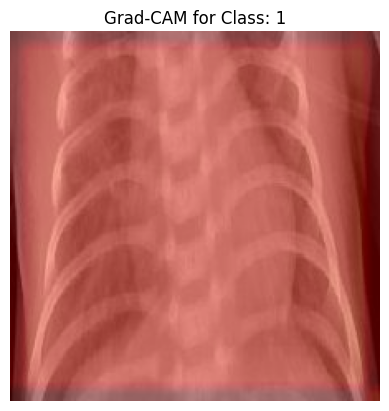


Generating Grad-CAM for layer: block3b_se_reduce...


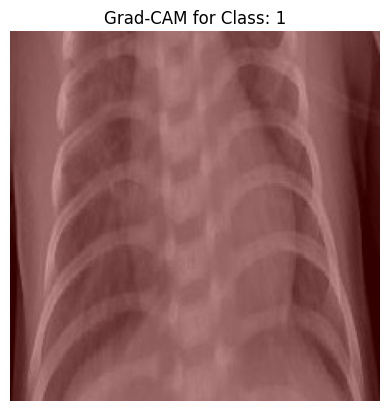


Generating Grad-CAM for layer: block3b_se_expand...


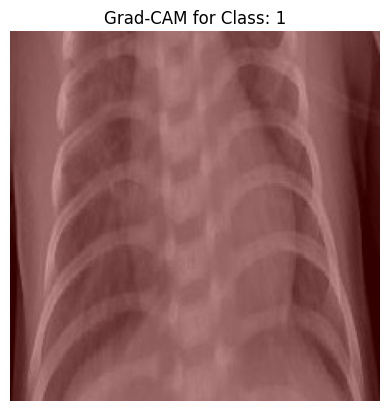


Generating Grad-CAM for layer: block3b_project_conv...


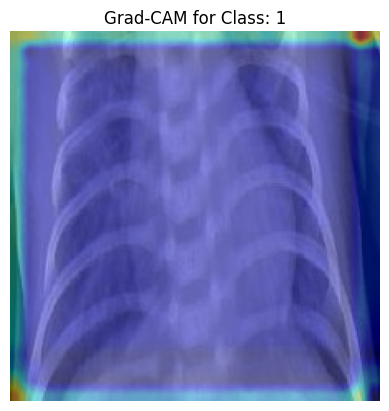


Generating Grad-CAM for layer: block4a_expand_conv...


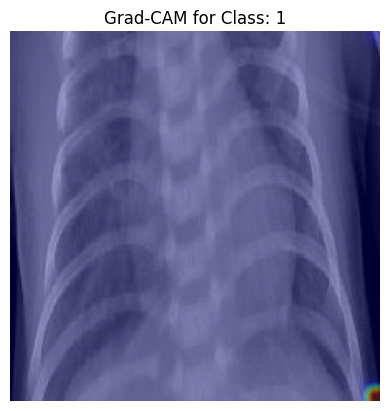


Generating Grad-CAM for layer: block4a_se_reduce...


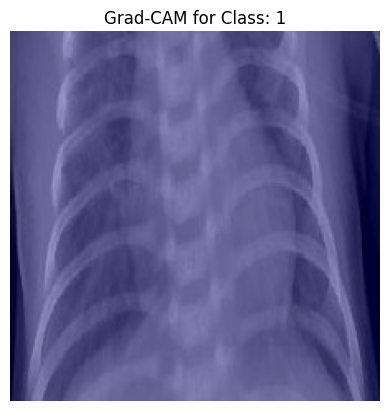


Generating Grad-CAM for layer: block4a_se_expand...


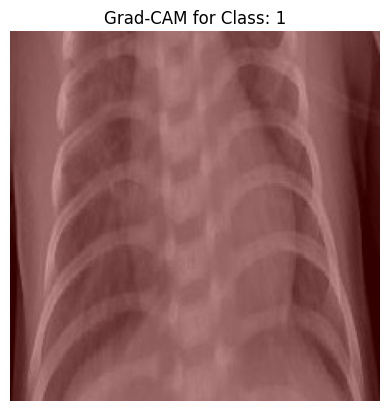


Generating Grad-CAM for layer: block4a_project_conv...


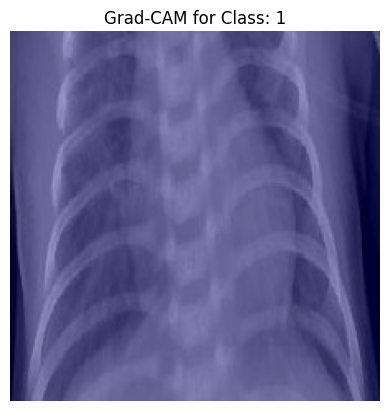


Generating Grad-CAM for layer: block4b_expand_conv...


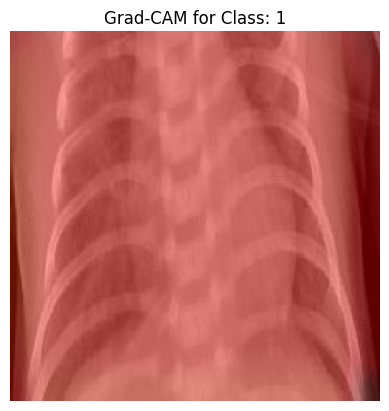


Generating Grad-CAM for layer: block4b_se_reduce...


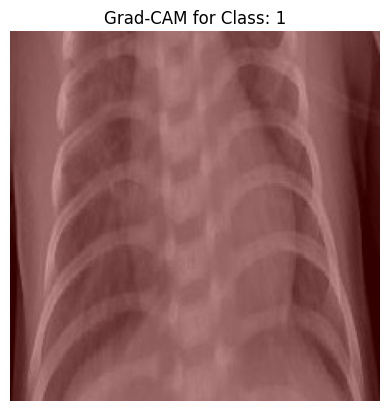


Generating Grad-CAM for layer: block4b_se_expand...


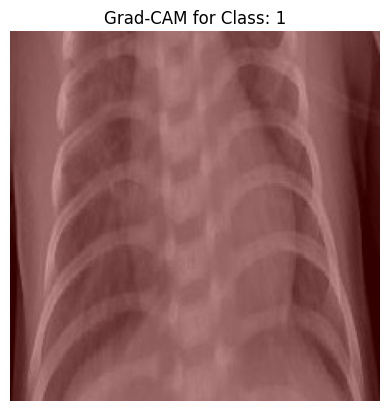


Generating Grad-CAM for layer: block4b_project_conv...


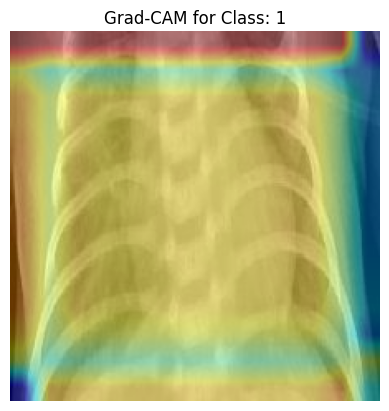


Generating Grad-CAM for layer: block4c_expand_conv...


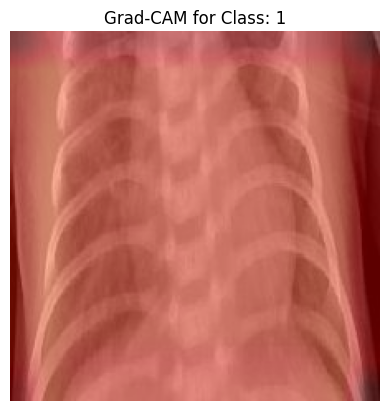


Generating Grad-CAM for layer: block4c_se_reduce...


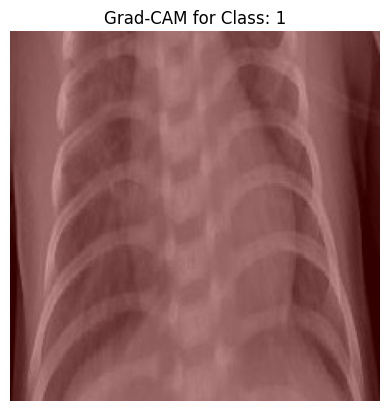


Generating Grad-CAM for layer: block4c_se_expand...


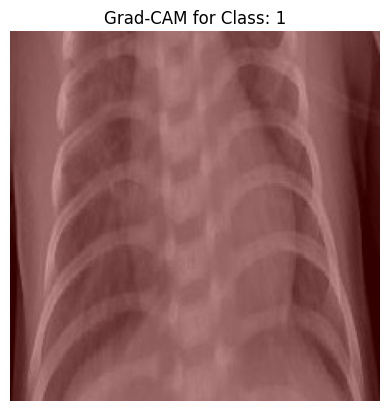


Generating Grad-CAM for layer: block4c_project_conv...


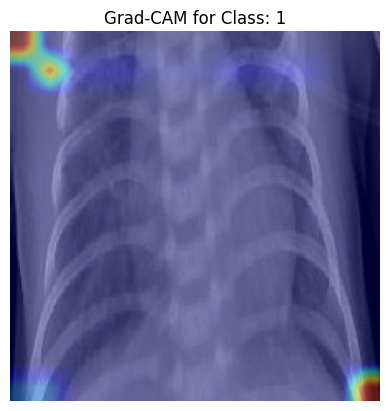


Generating Grad-CAM for layer: block5a_expand_conv...


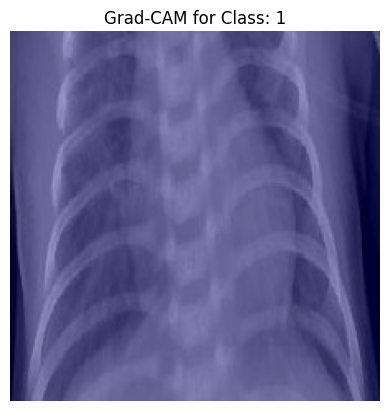


Generating Grad-CAM for layer: block5a_se_reduce...


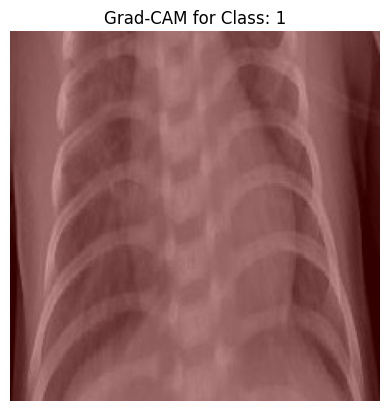


Generating Grad-CAM for layer: block5a_se_expand...


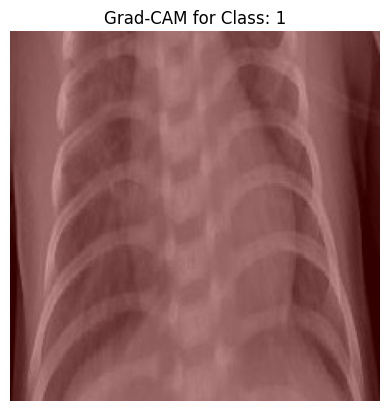


Generating Grad-CAM for layer: block5a_project_conv...


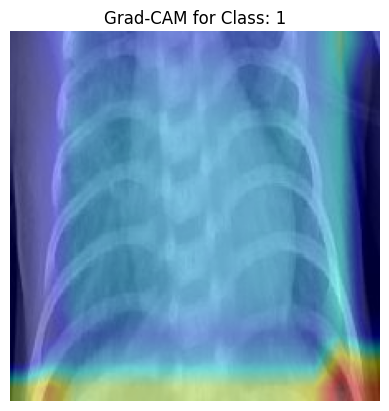


Generating Grad-CAM for layer: block5b_expand_conv...


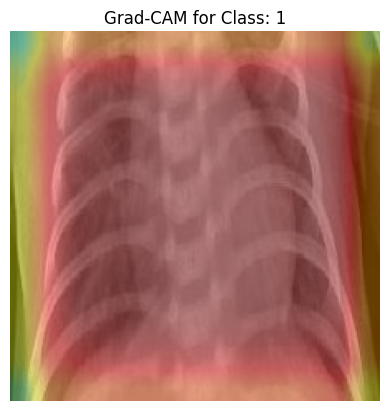


Generating Grad-CAM for layer: block5b_se_reduce...


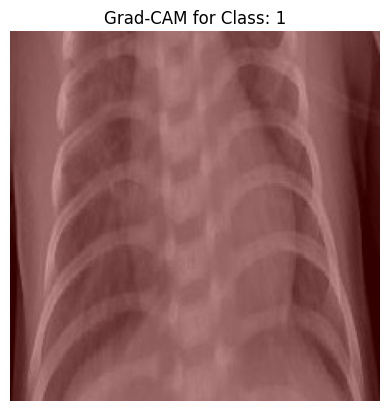


Generating Grad-CAM for layer: block5b_se_expand...


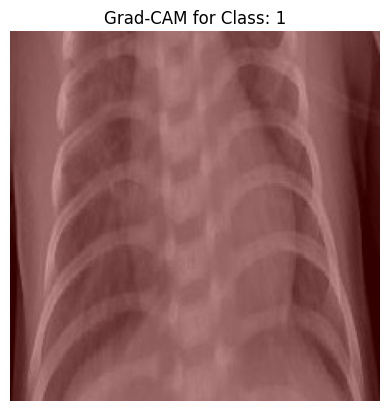


Generating Grad-CAM for layer: block5b_project_conv...


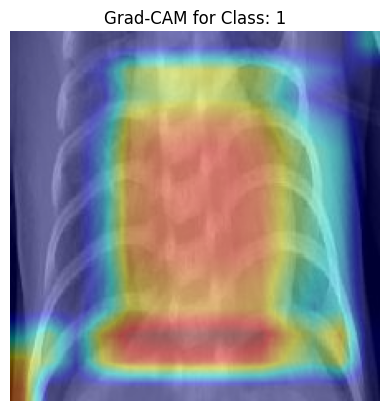


Generating Grad-CAM for layer: block5c_expand_conv...


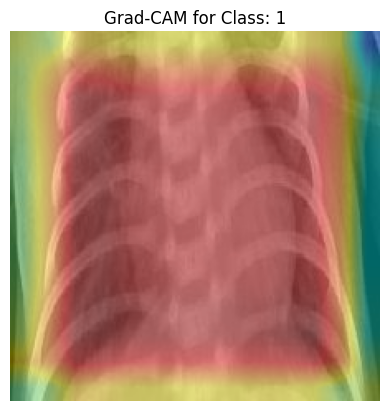


Generating Grad-CAM for layer: block5c_se_reduce...


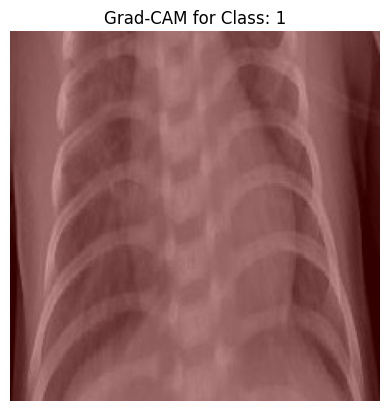


Generating Grad-CAM for layer: block5c_se_expand...


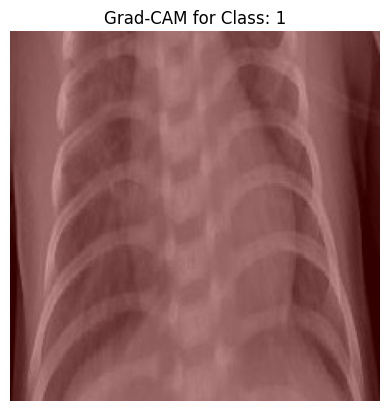


Generating Grad-CAM for layer: block5c_project_conv...


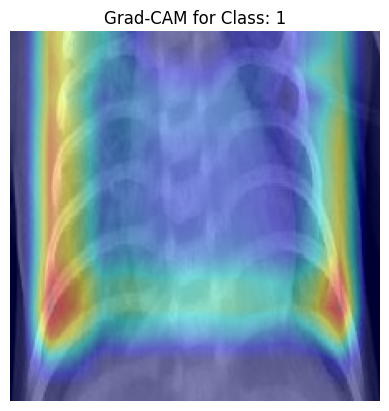


Generating Grad-CAM for layer: block6a_expand_conv...


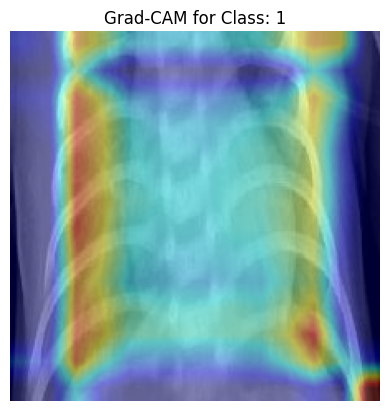


Generating Grad-CAM for layer: block6a_se_reduce...


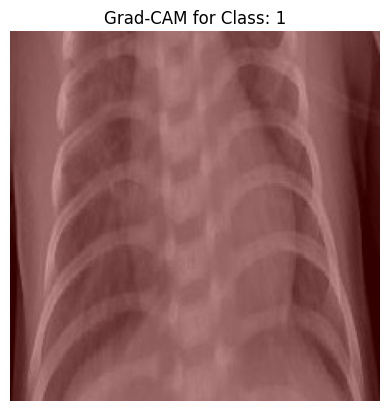


Generating Grad-CAM for layer: block6a_se_expand...


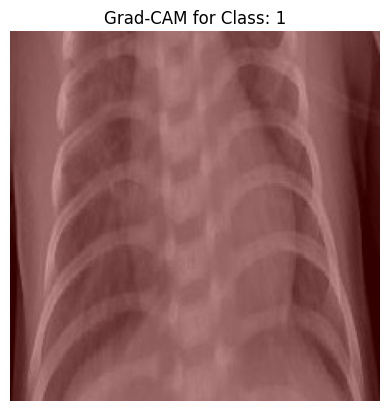


Generating Grad-CAM for layer: block6a_project_conv...


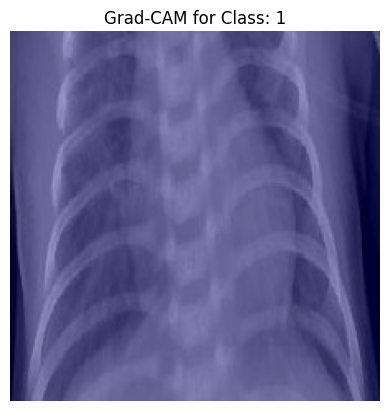


Generating Grad-CAM for layer: block6b_expand_conv...


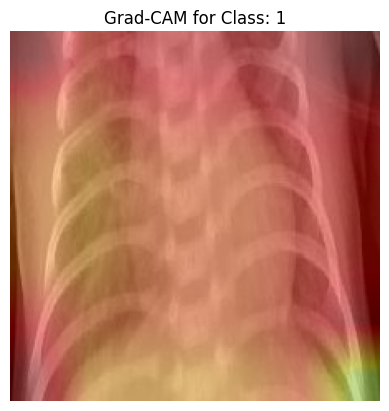


Generating Grad-CAM for layer: block6b_se_reduce...


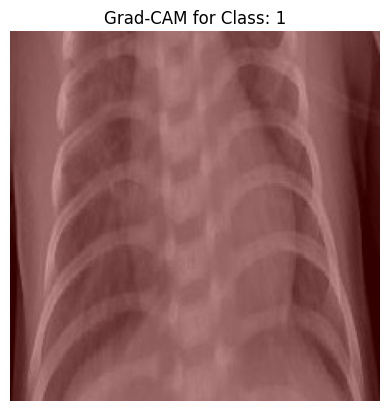


Generating Grad-CAM for layer: block6b_se_expand...


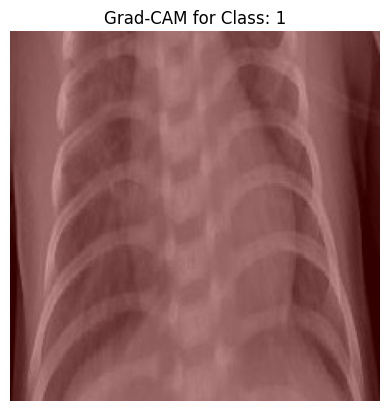


Generating Grad-CAM for layer: block6b_project_conv...


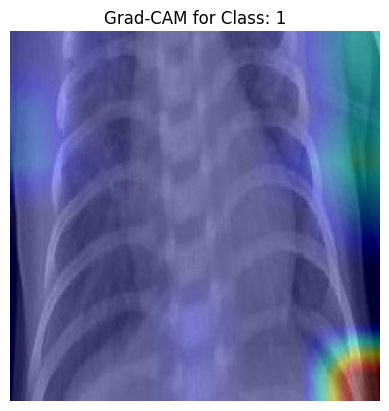


Generating Grad-CAM for layer: block6c_expand_conv...


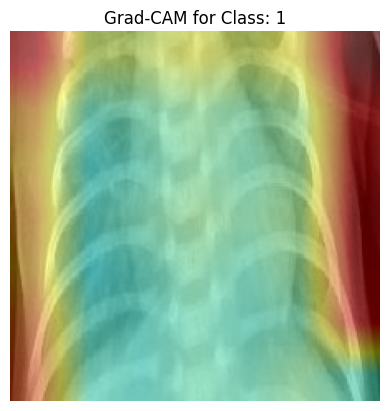


Generating Grad-CAM for layer: block6c_se_reduce...


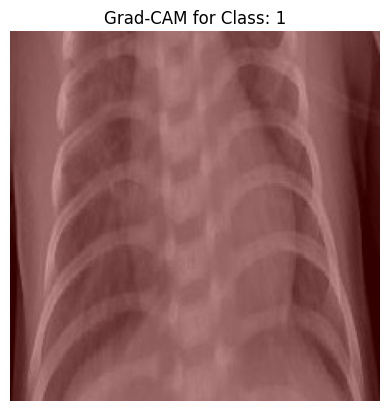


Generating Grad-CAM for layer: block6c_se_expand...


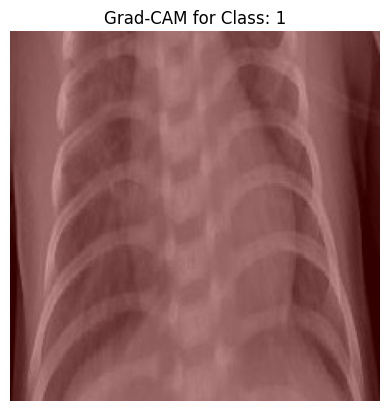


Generating Grad-CAM for layer: block6c_project_conv...


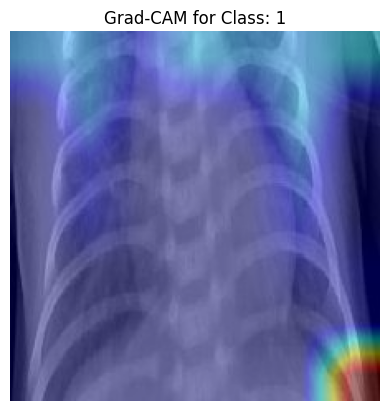


Generating Grad-CAM for layer: block6d_expand_conv...


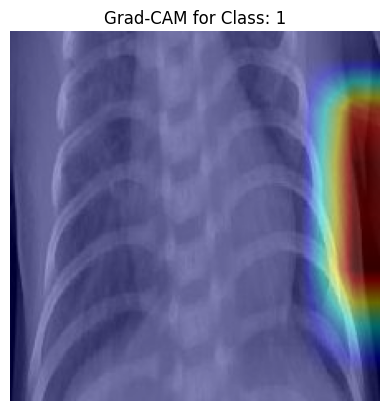


Generating Grad-CAM for layer: block6d_se_reduce...


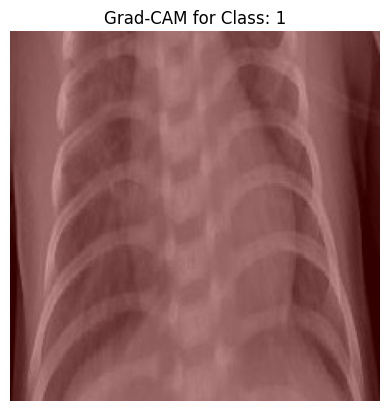


Generating Grad-CAM for layer: block6d_se_expand...


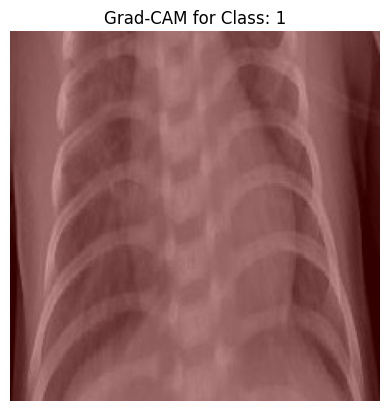


Generating Grad-CAM for layer: block6d_project_conv...


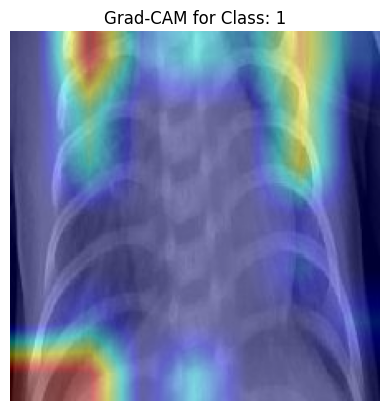


Generating Grad-CAM for layer: block7a_expand_conv...


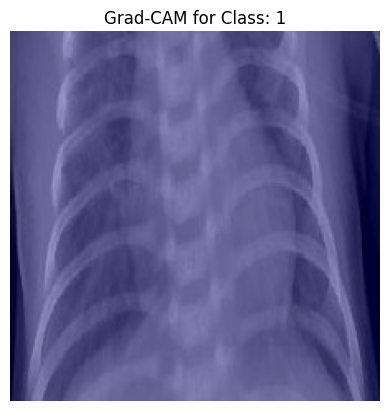


Generating Grad-CAM for layer: block7a_se_reduce...


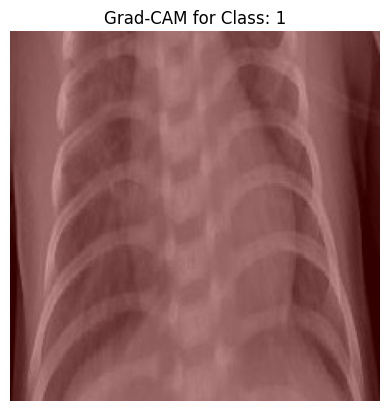


Generating Grad-CAM for layer: block7a_se_expand...


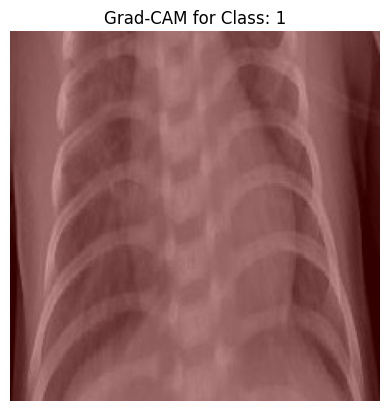


Generating Grad-CAM for layer: block7a_project_conv...


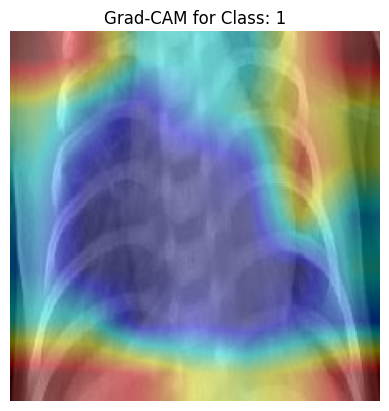


Generating Grad-CAM for layer: top_conv...


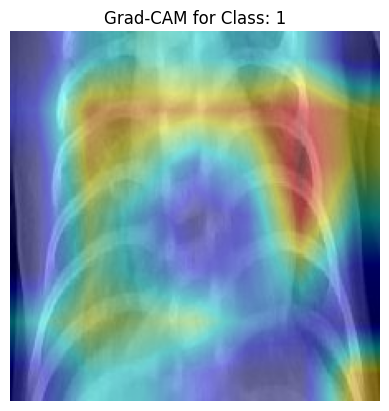

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2
import os
from tensorflow.keras.models import Model
from tensorflow.keras.utils import load_img, img_to_array

def load_model(model_path):
    """Load the trained model without the optimizer."""
    return tf.keras.models.load_model(model_path, compile=False)

def preprocess_image(image_path, target_size=(224, 224)):
    """Preprocess a single image."""
    img = load_img(image_path, target_size=target_size)
    img_array = img_to_array(img) / 255.0  # Normalize to [0, 1]
    img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension
    return img, img_array

def predict_single_image(model, image_path, class_names):
    """Predict the class of a single image."""
    img_original, img_array = preprocess_image(image_path)

    predictions = model.predict(img_array)
    predicted_class = np.argmax(predictions)
    class_idx = np.argmax(predictions)
    confidence = predictions[0][predicted_class] * 100

    result_text = f"Prediction: {class_names[predicted_class]} with probability {confidence:.2f}%"
    print(result_text)

    # Display the image with prediction
    plt.imshow(img_original)
    plt.title(result_text)
    plt.axis("off")
    plt.show()

    return class_idx

def display_gradcam(model, image_path, class_idx, layer_name):
    """Generate and display Grad-CAM for a single image."""
    # Preprocess the image
    img_original, img_array = preprocess_image(image_path)

    # Create a model mapping input to activations of the chosen layer and output predictions
    grad_model = Model(
        inputs=model.input,
        outputs=[model.get_layer(layer_name).output, model.output]
    )

    # Compute the gradient of the class output with respect to the feature map
    with tf.GradientTape() as tape:
        inputs = tf.convert_to_tensor(img_array)  # Use the image array directly
        conv_outputs, predictions = grad_model(inputs)
        loss = predictions[:, class_idx]  # Focus on the desired class output

    # Compute the gradients of the loss w.r.t. the output feature map
    grads = tape.gradient(loss, conv_outputs)[0]
    grads = tf.maximum(grads, 0)  # ReLU for positive gradients
    grads /= tf.reduce_max(grads) + 1e-8  # Normalize gradients

    # Weighted sum of feature map
    weights = tf.reduce_mean(grads, axis=(0, 1))  # Global average pooling on gradients
    cam = np.dot(conv_outputs[0], weights.numpy())  # Weighted sum

    # Normalize CAM
    cam = np.maximum(cam, 0)
    cam = cam / (np.max(cam) + 1e-8)

    # Resize heatmap to match original image size
    heatmap = cv2.resize(cam, (img_original.size[0], img_original.size[1]))
    heatmap = (heatmap * 255).astype("uint8")
    heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)

    # Overlay heatmap on the original image
    overlay = cv2.addWeighted(cv2.cvtColor(np.array(img_original), cv2.COLOR_RGB2BGR), 0.6, heatmap, 0.4, 0)

    # Display the Grad-CAM overlay
    plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
    plt.title(f"Grad-CAM for Class: {class_idx}")
    plt.axis("off")
    plt.show()

###############################################################################################################################################

def generate_gradcam_for_all_layers(model, image_path, class_idx, layer_names):
    """Generate Grad-CAM for multiple layers."""
    img_original, _ = preprocess_image(image_path)
    
    for layer_name in layer_names:
        try:
            print(f"\nGenerating Grad-CAM for layer: {layer_name}...")
            display_gradcam(model, image_path, class_idx, layer_name=layer_name)
        except Exception as e:
            print(f"Skipping layer {layer_name}: {str(e)}")
            
###############################################################################################################################################

def main():
    model_path = r"C:\Users\Legion\Desktop/pneumo/efficent_net/Model/Effiecent_net_Pneumo2.keras"
    single_image_path = r"C:\Users\Legion\Desktop\pneumo\data\processed\train\PNEUMONIA\person342_virus_702.jpeg"
    class_names = ["Normal", "Pneumonia"]

    # Load the model
    print("Loading the model...")
    model = load_model(model_path)

    # Predict on a single image and get the class index
    print("\nTesting prediction on a single image...")
    class_idx = predict_single_image(model, single_image_path, class_names)
    
    # See a sum of the model
    #model.summary()

    # Display Grad-CAM
    # Each layer has it's own grad-cam shit so make sure to choose what u find the best i guess from your perspective :|
    """print("\nGenerating Grad-CAM...")
    display_gradcam(model, single_image_path, class_idx, layer_name="top_conv")"""
    
    
    ###############################################################################################################################################
    
    # Get all layer names that could work for Grad-CAM
    layer_names = [layer.name for layer in model.layers if isinstance(layer, tf.keras.layers.Conv2D)]

    # Display Grad-CAM for each layer
    generate_gradcam_for_all_layers(model, single_image_path, class_idx, layer_names)
    
    ###############################################################################################################################################


if __name__ == "__main__":
    main()